# VLM 학습 데이터 준비

자체 생성 장난감 데이터 대신, 실제 공개 데이터셋인 **[Tutoruslabs/ChartQA_KOR](https://huggingface.co/datasets/Tutoruslabs/ChartQA_KOR)**
를 내려받아 fine-tuning 데이터 포맷으로 정리하고, 학생들이 공유해서 쓸 수 있도록
**HuggingFace Hub에 업로드**합니다. 이후 노트북들은 이 Hub 데이터셋을 다운로드해서 사용합니다.

- 이미지: 차트(막대/선/파이 등) 이미지
- 질문/답변: 차트 내용에 대한 한국어 질문과 정답(숫자 또는 단답)
- 포맷: `image` + `conversations` instruction-following JSON (LLM instruction tuning 포맷에 이미지가 추가된 형태)

> ⚠️ 원본 데이터셋은 **gated**(이용약관 동의 필요)이고, **평가(benchmark)용으로 test split(2,000개)만** 제공됩니다.
> 이 노트북에서 test split을 train/val로 나눠 업로드합니다.

## 사전 준비
1. https://huggingface.co/datasets/Tutoruslabs/ChartQA_KOR 페이지에서 로그인 후 이용약관에 동의
2. `.env.example`을 `.env`로 복사하고 `HF_TOKEN`(write 권한), `HF_DATASET_REPO_ID`(예: `your-username/chartqa-kor-vlm-lab`)를 채워넣기
```bash
cp .env.example .env
uv sync
```


In [1]:
import os

from dotenv import load_dotenv

import vlm_finetune_utils as vu

load_dotenv()

HF_TOKEN = os.environ["HF_TOKEN"]
HF_DATASET_REPO_ID = os.environ["HF_DATASET_REPO_ID"]


## 1. 데이터셋 다운로드 및 train/val 분할
`Tutoruslabs/ChartQA_KOR`의 test split(2,000개)을 8:2로 나눠 `data/train`, `data/val`에 저장합니다.

In [2]:
vu.prepare_chartqa_kor("data", val_ratio=0.2, seed=0)
print("생성 완료")


D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


생성 완료


## 2. 샘플 확인

C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 50640 (\N{HANGUL SYLLABLE E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\good593\AppData\Local\Temp\ipykernel_28744\1059168828.py:12: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) mi

D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50640 (\N{HANGUL SYLLABLE E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine T

D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine Tuning\examples\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\develop\github\course_VLM\5. VLM Fine 

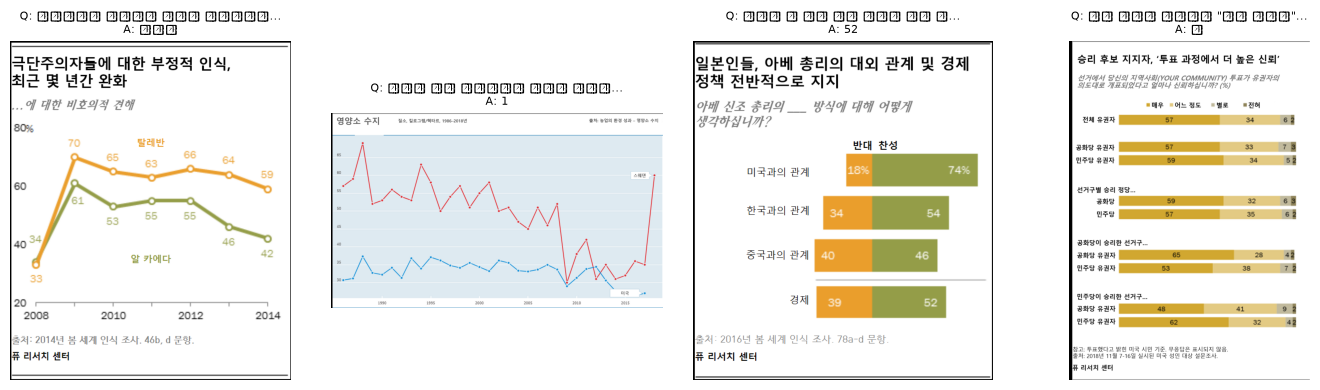

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

records = vu.load_jsonl("data/train/annotations.jsonl")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, r in zip(axes, records[:4]):
    img = Image.open(f"data/train/{r['image']}")
    ax.imshow(img)
    ax.set_title(f"Q: {r['question'][:20]}...\nA: {r['answer']}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
records[0]


{'image': 'images/0000.png',
 'question': '그래프에서 주황색은 무엇을 나타냅니까?',
 'answer': '탈레반',
 'conversations': [{'from': 'human',
   'value': '<image>\n그래프에서 주황색은 무엇을 나타냅니까?\n질문에 대한 답만 아주 간결하게 말하세요. 숫자면 숫자만, 단답이면 단답만 답하고 설명은 덧붙이지 마세요.'},
  {'from': 'gpt', 'value': '탈레반'}]}

## 3. 데이터 품질 체크리스트
fine-tuning 데이터에서 중요한 **답변 형태 분포 / 길이**를 코드로 직접 확인합니다.

In [5]:
from collections import Counter

answer_types = Counter(
    "숫자" if vu.is_numeric_answer(r["answer"]) else "텍스트" for r in records
)
answer_lengths = [len(r["answer"]) for r in records]

print("답변 타입 분포:", answer_types)
print(f"답변 평균 길이: {sum(answer_lengths) / len(answer_lengths):.1f}자")


답변 타입 분포: Counter({'숫자': 1048, '텍스트': 551})
답변 평균 길이: 3.5자


숫자 답변과 텍스트 답변이 섞여 있는 것을 확인할 수 있습니다. `judge_answer`는 숫자 답변에는
5% 오차까지 허용하는 relaxed accuracy를, 텍스트 답변에는 정규화 후 완전 일치를 적용합니다
(ChartQA 공식 평가 방식). 평가/VERA 노트북에서 이 기준으로 정답 여부를 판정합니다.

## 4. HuggingFace Hub 업로드
정리된 `data/train`, `data/val`을 `HF_DATASET_REPO_ID`에 업로드합니다. 이후 노트북들(2, 3, 4, 5)은
이 repo에서 데이터를 내려받아 사용하므로, 로컬 `data/` 폴더가 없는 새 환경(예: RunPod Pod)에서도
동일한 데이터로 실습할 수 있습니다.

In [6]:
vu.push_dataset_to_hub("data", HF_DATASET_REPO_ID, private=False, token=HF_TOKEN)
print(f"업로드 완료: https://huggingface.co/datasets/{HF_DATASET_REPO_ID}")


Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/1599 [00:00<?, ? examples/s]

Map:  33%|███▎      | 528/1599 [00:02<00:04, 225.15 examples/s]

Map:  66%|██████▌   | 1056/1599 [00:04<00:02, 235.66 examples/s]

Map:  99%|█████████▉| 1584/1599 [00:06<00:00, 234.45 examples/s]

... (894 outputs left out)


New Data Upload: 100%|██████████| 55.6MB / 55.6MB, 2.03MB/s  


Uploading the dataset shards: 100%|██████████| 1/1 [00:29<00:00, 29.65s/ shards]

Uploading the dataset shards: 100%|██████████| 1/1 [00:29<00:00, 29.65s/ shards]

업로드 완료: https://huggingface.co/datasets/good593/chartqa-kor-vlm-lab


## 정리
- `data/train/annotations.jsonl`, `data/val/annotations.jsonl`에 학습/검증 데이터가 로컬로 저장됨
- 같은 데이터가 `HF_DATASET_REPO_ID`(HuggingFace Hub)에도 업로드됨
- 다음 노트북들(`2. QLoRA Fine-tuning.ipynb` 등)은 `.env`의 `HF_DATASET_REPO_ID`에서 데이터를 다운로드해 사용